# B02 怎样合并多个气象站并按城市统计？

把分散的记录纵向合并，再把站点属性横向连接。区分 concat 与 merge，发现遗漏站点，并用同一任务练习可选 SQLite 查询。

先修：B01；本例首次引入 DataFrame、按列选择、分组和连接。

本案例所有输入来自本地；无需联网。

**环境准备：** 下一格设置本地路径、离线模式和图表字体，直接运行即可，暂时不需要掌握所有设置。真正的解题步骤从后面的中文小节开始。

In [1]:
from pathlib import Path
import os
os.environ.setdefault("HF_HUB_OFFLINE", "1")
os.environ.setdefault("TRANSFORMERS_OFFLINE", "1")
os.environ.setdefault("HF_HUB_DISABLE_TELEMETRY", "1")
os.environ.setdefault("OMP_NUM_THREADS", "2")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
CASE_DIR = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
COURSE_ROOT = CASE_DIR.parents[1]
DATA_DIR = CASE_DIR / "data"
OUT_DIR = CASE_DIR / "outputs"
OUT_DIR.mkdir(exist_ok=True)
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
plt.rcParams.update({"font.family": "Microsoft YaHei", "axes.unicode_minus": False,
                     "figure.figsize": (8, 4.5), "figure.dpi": 110})


## 1. 多文件读取：每个文件是一块同结构数据
`glob` 找匹配文件，`sorted` 固定处理顺序。列表推导生成多个 DataFrame；`concat` 连接行，不会按站点自动匹配。保留来源文件便于追查。

In [2]:
import pandas as pd, json
frames = []
for path in sorted(DATA_DIR.glob('station_*.csv')):
    frame = pd.read_csv(path, parse_dates=['date'])
    frame['source'] = path.name
    frames.append(frame)
weather = pd.concat(frames, ignore_index=True)
assert len(weather) == 9
assert not weather.duplicated(['station', 'date']).any()
print(weather.head())


  station       date  temp_max         source
0       A 2024-07-01        25  station_A.csv
1       A 2024-07-02        27  station_A.csv
2       A 2024-07-03        29  station_A.csv
3       B 2024-07-01        27  station_B.csv
4       B 2024-07-02        29  station_B.csv


## 2. 属性连接：站点表必须一站一行
`many_to_one` 要求右表键唯一，避免一次合并把记录数翻倍。左连接保留所有天气记录；缺失城市必须查清，不能默默丢弃。

In [3]:
stations = pd.read_csv(DATA_DIR / 'stations.csv')
merged = weather.merge(stations, on='station', how='left', validate='many_to_one')
assert len(merged) == len(weather)
assert merged['city'].notna().all()
print(merged[['station', 'city', 'date', 'temp_max']])


  station city       date  temp_max
0       A   海城 2024-07-01        25
1       A   海城 2024-07-02        27
2       A   海城 2024-07-03        29
3       B   海城 2024-07-01        27
4       B   海城 2024-07-02        29
5       B   海城 2024-07-03        31
6       C   山城 2024-07-01        21
7       C   山城 2024-07-02        23
8       C   山城 2024-07-03        25


## 3. 分组：一行代表什么会改变平均值
先算每个城市每天的站点平均，再跨天平均，避免站点较多的一天被额外加权。分组后的表是新的分析单位。`pivot` 将日期变成行、城市变成列。

In [4]:
city_day = merged.groupby(['city', 'date'], as_index=False)['temp_max'].mean()
summary = city_day.groupby('city')['temp_max'].agg(['mean', 'max', 'count'])
daily_wide = city_day.pivot(index='date', columns='city', values='temp_max')
print(summary)
assert len(city_day) == 6


      mean   max  count
city                   
山城    23.0  25.0      3
海城    28.0  30.0      3


## 4. 导出与检查：让另一人能复算
保存合并明细和城市日均表，同时输出样本量。城市间差异仅是这三天的教学样本差异，不应扩大为常年温度差异。

In [5]:
merged.to_csv(OUT_DIR / 'merged.csv', index=False, encoding='utf-8-sig')
city_day.to_csv(OUT_DIR / 'city_daily.csv', index=False, encoding='utf-8-sig')
metrics = {'records': len(merged), 'city_days': len(city_day), 'means': summary['mean'].to_dict()}
(OUT_DIR / 'metrics.json').write_text(json.dumps(metrics, ensure_ascii=False, indent=2), encoding='utf-8')
daily_wide.plot(marker='o'); plt.ylabel('站点日最高温均值 / °C'); plt.tight_layout()
plt.savefig(OUT_DIR / 'city_comparison.png'); plt.close()


## 结果图与检查
下面展示本次计算保存的图。数值以单元格和 outputs 中的实际输出为准。

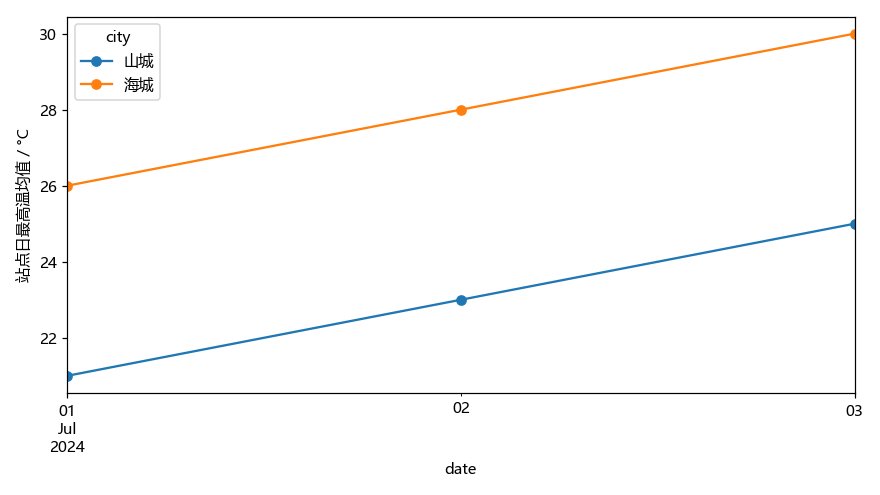

In [6]:
from IPython.display import display, Image
for figure in sorted(OUT_DIR.glob("*.png")):
    display(Image(filename=str(figure)))

## 适用边界与常见错误
同名字段不代表同一含义；单位必须一致。merge 的重复键会制造伪样本；缺失城市不能用内连接掩盖。SQLite 是可选迁移，不阻塞 pandas 主线。

## 独立练习
打开「动手练习.ipynb」，完成补全、修改、迁移，再查看「参考答案.ipynb」。